# 02 · Sentiment: what the text says vs what players voted

Every Steam review has a thumbs up or down (`recommended`). This notebook asks:

1. Can a standard sentiment tool (VADER) recover that vote from the text alone?
2. Where do text and vote disagree, and why?
3. Which words separate positive from negative reviews in each game?
4. Does text sentiment move over time the same way the thumbs do?

**Input:** `data/processed/reviews_clean.csv` (from notebook 01)  
**Output:** `data/processed/reviews_scored.csv` and charts in `images/`

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.model_selection import train_test_split

PROC = Path("../data/processed")
IMG = Path("../images")
IMG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 160)

df_all = pd.read_csv(PROC / "reviews_clean.csv", parse_dates=["month"])

# Text analysis only makes sense for reviews with 3+ words ("10/10" or "fun" carry no text signal).
# Vote-based numbers (% thumbs up over time) still use every review via df_all.
df = df_all[~df_all["is_short"]].copy()
print(f"{len(df_all):,} reviews in total, {len(df):,} with 3+ words used for text analysis, "
      f"{df['game'].nunique()} games")

298,001 reviews in total, 237,811 with 3+ words used for text analysis, 5 games


## 1. VADER sentiment score

VADER is a rule-based sentiment tool. `compound` runs from -1 (very negative) to +1 (very positive). It is fast and needs no training, so it is a good baseline, but it does not understand gaming slang or sarcasm.

In [2]:
analyzer = SentimentIntensityAnalyzer()
df["vader"] = df["review"].map(lambda t: analyzer.polarity_scores(t)["compound"])

def to_label(x):
    if x >= 0.05:
        return "positive"
    if x <= -0.05:
        return "negative"
    return "neutral"

df["vader_label"] = df["vader"].map(to_label)
df["vader_label"].value_counts(normalize=True).round(3)

vader_label
positive    0.756
negative    0.148
neutral     0.097
Name: proportion, dtype: float64

## 2. How well does VADER match the thumbs up/down?

In [3]:
scored = df[df["vader_label"] != "neutral"].copy()
scored["vader_pred"] = (scored["vader_label"] == "positive").astype(int)

overall = pd.Series({
    "accuracy": accuracy_score(scored["recommended"], scored["vader_pred"]),
    "f1": f1_score(scored["recommended"], scored["vader_pred"]),
    "roc_auc (using the raw score)": roc_auc_score(scored["recommended"], scored["vader"]),
    "baseline accuracy (always guess 'positive')": scored["recommended"].mean(),
    "share of reviews VADER calls neutral": (df["vader_label"] == "neutral").mean(),
}).round(3)
overall

accuracy                                       0.861
f1                                             0.918
roc_auc (using the raw score)                  0.804
baseline accuracy (always guess 'positive')    0.855
share of reviews VADER calls neutral           0.097
dtype: float64

In [4]:
by_game = (scored.groupby("game")
    .apply(lambda g: pd.Series({
        "reviews": len(g),
        "baseline_acc": g["recommended"].mean(),
        "accuracy": accuracy_score(g["recommended"], g["vader_pred"]),
        "auc": roc_auc_score(g["recommended"], g["vader"]) if g["recommended"].nunique() > 1 else np.nan,
    }), include_groups=False)
    .round(3))
by_game

,reviews,baseline_acc,accuracy,auc
game,,,,
Battlefield 2042,27303.0,0.517,0.739,0.785
Cyberpunk 2077,37794.0,0.896,0.863,0.771
Helldivers 2,17198.0,0.732,0.758,0.733
No Man's Sky,64413.0,0.870,0.870,0.772
Stardew Valley,68057.0,0.985,0.926,0.785


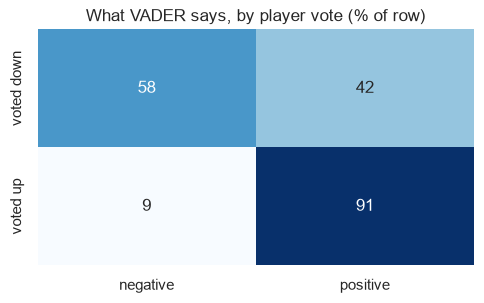

In [5]:
cm = pd.crosstab(scored["recommended"].map({1: "voted up", 0: "voted down"}),
                 scored["vader_label"], normalize="index") * 100

fig, ax = plt.subplots(figsize=(5, 3.2))
sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax)
ax.set(title="What VADER says, by player vote (% of row)", xlabel="", ylabel="")
fig.tight_layout()
fig.savefig(IMG / "vader_vs_vote.png", dpi=150)
plt.show()

**Read AUC, not accuracy.** Most reviews are thumbs up, so a tool that always says "positive" already scores the `baseline_acc` above. AUC measures how well the score *ranks* positive reviews above negative ones and is not inflated by that imbalance.

## 3. Where text and vote disagree

These are the interesting cases: a thumbs up with very negative wording, or a thumbs down with very positive wording. Read them before trusting any sentiment number.

In [6]:
up_but_negative = (df[(df["recommended"] == 1) & (df["vader"] <= -0.6)]
                   .sample(8, random_state=1, replace=False) if ((df["recommended"] == 1) & (df["vader"] <= -0.6)).sum() >= 8
                   else df[(df["recommended"] == 1) & (df["vader"] <= -0.6)])
up_but_negative[["game", "vader", "review"]]

,game,vader,review
138377,No Man's Sky,-0.7096,I'm in the throws of obsession. That's a bad time to write a review. I've had two weeks of thinking of nothing else. Ask me again later when the fever br...
81751,Cyberpunk 2077,-0.6369,"What to say about a game that has been reviewed, talked about, raged on and raved upon by so many gamers. \r\n\r\nMaybe.... the only thing we can say is - n..."
176848,No Man's Sky,-0.6808,Almost 8 years later and they're still updating the hell out of this game
211573,Stardew Valley,-0.6908,She told me she was allergic to the grass stains on my pants. 10/10 feels bad
200963,No Man's Sky,-0.6048,"Yes I would recommend No mans sky over all.. but the DEVS cant code their way out of a wet paper bag and the new ""Alliance"" leaderboard is the most RET....D..."
267276,Stardew Valley,-0.6597,Me and girlfriend are married with a scary child that always stands outside his crib at 6 in the morning with no emotion.
85247,Cyberpunk 2077,-0.8567,Keanu Reeves followed me around for 128 hours and told me I was a 'city-burning legend' every time I did something as simple as buying a burrito.\n\nHe’s an...
130462,No Man's Sky,-0.8573,"Bought it again, it's actually pretty okay for like $25.00 it's certainly not a ""$60 game"" but it's doing a hell of a lot better than it was two years ago.\..."


In [7]:
down_but_positive = df[(df["recommended"] == 0) & (df["vader"] >= 0.6)]
down_but_positive = down_but_positive.sample(min(8, len(down_but_positive)), random_state=1)
down_but_positive[["game", "vader", "review"]]

,game,vader,review
5703,Battlefield 2042,0.9377,"In EA's defense, they have given us a lot of updates that have improved what the game was at launch. However, this does not mean it is to the level of quali..."
41218,Cyberpunk 2077,0.9941,I've played it quite a bit so far. 86 hours as of this. I find it fun sure. Would I reccomend it? No. Nah brah. This game is the opposite of next gen. I mea...
29561,Battlefield 2042,0.9269,This was one of my saddest experiences in gaming. I have always (up until BF5) looged forward to the next instalment in this franchise. BF3 and BF4 are both...
37573,Battlefield 2042,0.8812,cool but it can get sweaty and bugs can appeer time to time..... so uhhhhhh.... save your money on something better
135482,No Man's Sky,0.7003,not even 2 hours into the game and it keeps crashing whenever i try to land on a planet :) nice game
147343,No Man's Sky,0.9968,"Please note that this review only applies if you are planning to play this game in VR. Before you say that ""You only have 2 hours of playtime! You can't lea..."
285179,Stardew Valley,0.9735,"this games okay, but gta's better 🤣🤣🤣🤣"
178373,No Man's Sky,0.7484,"While it seems to be better than launch, the amount of bugs and desync issues make it more frustrating than fun. I keep rage quitting, and then hoping on a ..."


**What to look for:** thumbs-up reviews that sound negative are often describing dark themes, bugs they put up with, or sarcasm ("this game ruined my sleep schedule, 10/10"). Thumbs-down reviews that sound positive are often "I love the idea, but it is broken". This is the main reason to use the player vote as ground truth and the text for the *why*.

## 4. Supervised baseline: predict the vote from the words

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    df["review"], df["recommended"], test_size=0.2, random_state=42, stratify=df["recommended"])

tfidf = TfidfVectorizer(min_df=5, ngram_range=(1, 2), stop_words="english", sublinear_tf=True, max_features=50000)
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)

clf = LogisticRegression(max_iter=1000, class_weight="balanced")
clf.fit(Xtr, y_train)
proba = clf.predict_proba(Xte)[:, 1]
pred = (proba >= 0.5).astype(int)

pd.Series({
    "accuracy": accuracy_score(y_test, pred),
    "f1": f1_score(y_test, pred),
    "roc_auc": roc_auc_score(y_test, proba),
}).round(3)

accuracy    0.908
f1          0.944
roc_auc     0.958
dtype: float64

A model trained on the actual votes should beat VADER, because it learns the words that matter in *this* domain (for example, "refund" or "crash"). If it does not, the text may carry little signal beyond what VADER already finds.

### Words that push a review toward thumbs up or down (all games)

In [9]:
terms = np.array(tfidf.get_feature_names_out())
coef = clf.coef_[0]
top_pos = pd.DataFrame({"word": terms[np.argsort(coef)[-15:][::-1]], "weight": np.sort(coef)[-15:][::-1].round(2)})
top_neg = pd.DataFrame({"word": terms[np.argsort(coef)[:15]], "weight": np.sort(coef)[:15].round(2)})
pd.concat([top_pos.add_prefix("up_"), top_neg.add_prefix("down_")], axis=1)

,up_word,up_weight,down_word,down_weight
0,10 10,9.25,boring,-8.51
1,amazing,9.02,refund,-8.21
2,love,8.32,arrowhead,-7.99
3,relaxing,7.43,worst,-7.50
4,best,7.12,ea,-7.25
5,masterpiece,6.72,garbage,-6.59
6,addictive,6.36,unplayable,-6.58
7,great,6.30,crashes,-6.35
8,fantastic,6.20,worse,-6.12
9,addicting,6.18,terrible,-5.85


### Distinctive words per game

In [10]:
rows = []
for game, g in df.groupby("game"):
    if g["recommended"].nunique() < 2 or len(g) < 200:
        continue
    vec = TfidfVectorizer(min_df=5, ngram_range=(1, 2), stop_words="english", sublinear_tf=True, max_features=20000)
    Xg = vec.fit_transform(g["review"])
    m = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xg, g["recommended"])
    t = np.array(vec.get_feature_names_out()); c = m.coef_[0]
    rows.append({"game": game,
                 "positive words": ", ".join(t[np.argsort(c)[-8:][::-1]]),
                 "negative words": ", ".join(t[np.argsort(c)[:8]])})
pd.DataFrame(rows)

,game,positive words,negative words
0,Battlefield 2042,"fun, good, great, best, love, sale, solid, amazing","garbage, worst, ea, refund, money, waste, tried, unplayable"
1,Cyberpunk 2077,"amazing, best, masterpiece, great, 10 10, favorite, perfect, great game","boring, crashes, terrible, refund, disappointment, crashing, tried, unplayable"
2,Helldivers 2,"democracy, best, great, fun, 10 10, amazing, love, good","arrowhead, devs, worse, fix, anymore, developers, unplayable, crashes"
3,No Man's Sky,"love, amazing, great, 10 10, awesome, relaxing, great game, best","boring, refund, unplayable, worst, tried, terrible, worse, crashes"
4,Stardew Valley,"10 10, best, amazing, love game, perfect, relaxing, addicting, great game","boring, refund, awful, good great, gba, slow, tedious, worst"


## 5. Sentiment over time: text vs thumbs

In [11]:
# Sanity check: how many reviews sit behind the most recent months?
(df_all.groupby(["game", "month"]).size().rename("n").reset_index()
   .sort_values("month").groupby("game").tail(3).sort_values(["game", "month"]))

,game,month,n
57,Battlefield 2042,2026-08-01,160
58,Battlefield 2042,2026-09-01,115
59,Battlefield 2042,2026-10-01,98
128,Cyberpunk 2077,2026-08-01,766
129,Cyberpunk 2077,2026-09-01,768
130,Cyberpunk 2077,2026-10-01,771
161,Helldivers 2,2026-08-01,762
162,Helldivers 2,2026-09-01,763
163,Helldivers 2,2026-10-01,774
284,No Man's Sky,2026-08-01,763


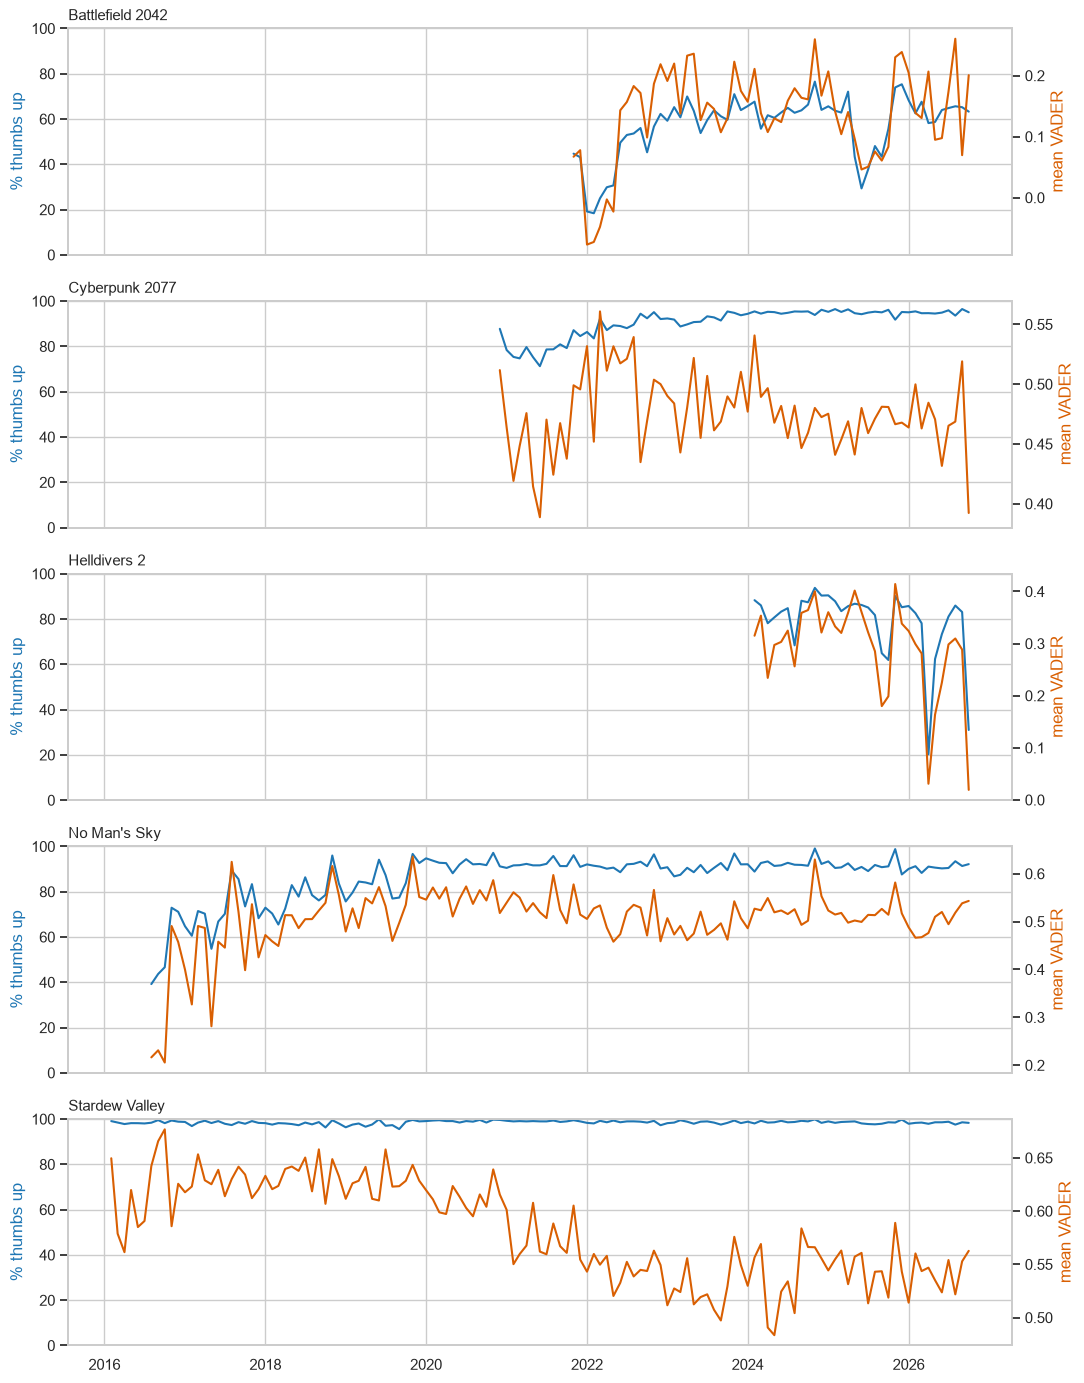

In [12]:
MIN_N = 30
votes = (df_all.groupby(["game", "month"])
                .agg(pct_positive=("recommended", "mean"), n=("recommended", "size")))
text = df.groupby(["game", "month"]).agg(vader=("vader", "mean"))
m = votes.join(text).reset_index()
if (m["n"] >= MIN_N).any():
    m = m[m["n"] >= MIN_N]
else:
    print(f"No month has {MIN_N}+ reviews, showing all months (values will be noisy)")
m["pct_positive"] *= 100

games = m["game"].unique()
fig, axes = plt.subplots(len(games), 1, figsize=(11, 2.8 * len(games)), sharex=True)
axes = np.atleast_1d(axes)
for ax, game in zip(axes, games):
    g = m[m["game"] == game]
    ax.plot(g["month"], g["pct_positive"], color="#1f77b4", label="% thumbs up")
    ax.set_ylabel("% thumbs up", color="#1f77b4"); ax.set_ylim(0, 100)
    ax2 = ax.twinx()
    ax2.plot(g["month"], g["vader"], color="#d95f02", label="mean VADER")
    ax2.set_ylabel("mean VADER", color="#d95f02"); ax2.grid(False)
    ax.set_title(game, loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(IMG / "sentiment_over_time.png", dpi=150)
plt.show()

### Does review length change over time?

Stardew Valley stays about 98% thumbs up, but its text sentiment drifts down. One explanation is that reviews get shorter and more casual. This checks it.

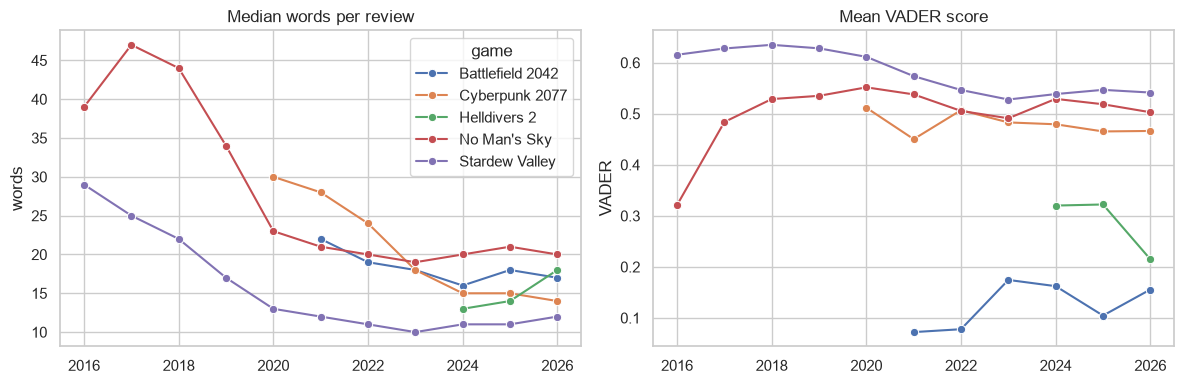

In [13]:
yr = (df.groupby(["game", "year"] if "year" in df.columns else ["game", df["month"].dt.year.rename("year")])
        .agg(median_words=("word_count", "median"), mean_vader=("vader", "mean"), n=("vader", "size"))
        .reset_index())
yr = yr[yr["n"] >= 100]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=yr, x="year", y="median_words", hue="game", marker="o", ax=axes[0])
axes[0].set(title="Median words per review", xlabel="", ylabel="words")
sns.lineplot(data=yr, x="year", y="mean_vader", hue="game", marker="o", ax=axes[1], legend=False)
axes[1].set(title="Mean VADER score", xlabel="", ylabel="VADER")
fig.tight_layout()
fig.savefig(IMG / "length_and_sentiment_by_year.png", dpi=150)
plt.show()

## 6. Optional: a transformer model

A pretrained transformer usually handles sarcasm and slang better than VADER. It is slow on CPU, so it runs on a **sample** and is switched off by default. Set `USE_TRANSFORMER = True` and install `transformers` and `torch` first.

In [14]:
USE_TRANSFORMER = False
SAMPLE = 3000

if USE_TRANSFORMER:
    from transformers import pipeline
    clf_tf = pipeline("sentiment-analysis", model="cardiffnlp/twitter-roberta-base-sentiment-latest",
                      truncation=True, max_length=256)
    s = df.sample(min(SAMPLE, len(df)), random_state=1).copy()
    out = clf_tf(s["review"].tolist(), batch_size=32)
    s["tf_label"] = [o["label"].lower() for o in out]
    s = s[s["tf_label"] != "neutral"]
    s["tf_pred"] = (s["tf_label"] == "positive").astype(int)
    print("transformer accuracy:", round(accuracy_score(s["recommended"], s["tf_pred"]), 3))
    s2 = s.copy(); s2["vader_pred"] = (s2["vader"] >= 0.05).astype(int)
    print("VADER accuracy on same sample:", round(accuracy_score(s2["recommended"], s2["vader_pred"]), 3))
else:
    print("Transformer step skipped (USE_TRANSFORMER = False)")

Transformer step skipped (USE_TRANSFORMER = False)


## 7. Save

In [15]:
keep = ["recommendationid", "game", "month", "recommended", "playtime_hours", "playtime_bucket",
        "word_count", "vader", "vader_label", "review"]
df[keep].to_csv(PROC / "reviews_scored.csv", index=False)
print(f"saved {len(df):,} scored reviews")

saved 237,811 scored reviews
